# RAG without a vector database: an embedding-free document agent with Nemotron 3.5 Super VL

Author: [Zain Hasan](https://x.com/ZainHasan6)

<a target="_blank" href="https://colab.research.google.com/github/togethercomputer/together-cookbook/blob/main/agents/Embedding_Free_Document_Agent.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Introduction

The usual way to answer questions over a PDF is retrieval-augmented generation: chunk the text, embed the chunks, store them in a vector database, and retrieve the nearest chunks for each question. That works poorly on slide decks and reports, because their important numbers sit in charts. The PDF text layer either lacks those numbers or lists them in a jumbled order with nothing tying them to their labels. The pipeline also has moving parts to build and keep in sync with the documents: a chunker, an embedding model, an index, and often a reranker.

This notebook tries something simpler. We give a vision-language model three tools (keyword search over the text layer, a page viewer, and a zoom) and let it work through the document the way a person would: find the likely page, look at it, and zoom in on the chart when the labels are small. There are no embeddings and no vector database.

We use [NVIDIA Nemotron 3.5 Super VL](https://api.together.ai/models/nvidia/NVIDIA-Nemotron-3.5-Super-VL) on Together AI, which combines image input with function calling, and test it on NVIDIA's own 39-page investor presentation.

| | |
| :-- | :-- |
| Model | `nvidia/NVIDIA-Nemotron-3.5-Super-VL` |
| Context length | 262,144 tokens |
| Images per request | Up to 32 |
| Pricing (per 1M tokens) | \$0.15 input, \$0.50 output |
| Features used | Image input, function calling |

## Setup

In [1]:
%pip install -qU "together>=3.0.0" "pymupdf>=1.26.7" "pillow>=11.3.0" "requests>=2.33.0" "pandas>=2.0.0" matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64
import io
import json
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf
import requests
from IPython.display import Markdown, display
from PIL import Image, ImageDraw, ImageFont
from together import Together

# Reads TOGETHER_API_KEY from the environment
client = Together()

MODEL = "nvidia/NVIDIA-Nemotron-3.5-Super-VL"
PRICE_IN, PRICE_OUT = 0.15, 0.50  # $ per 1M tokens

## Load the document

We download NVIDIA's October 2023 investor presentation and open it with [PyMuPDF](https://pymupdf.readthedocs.io), which renders pages to images and reads the text layer. PyMuPDF is a pip install with no system dependencies, so this works the same locally and in Colab.

39 pages


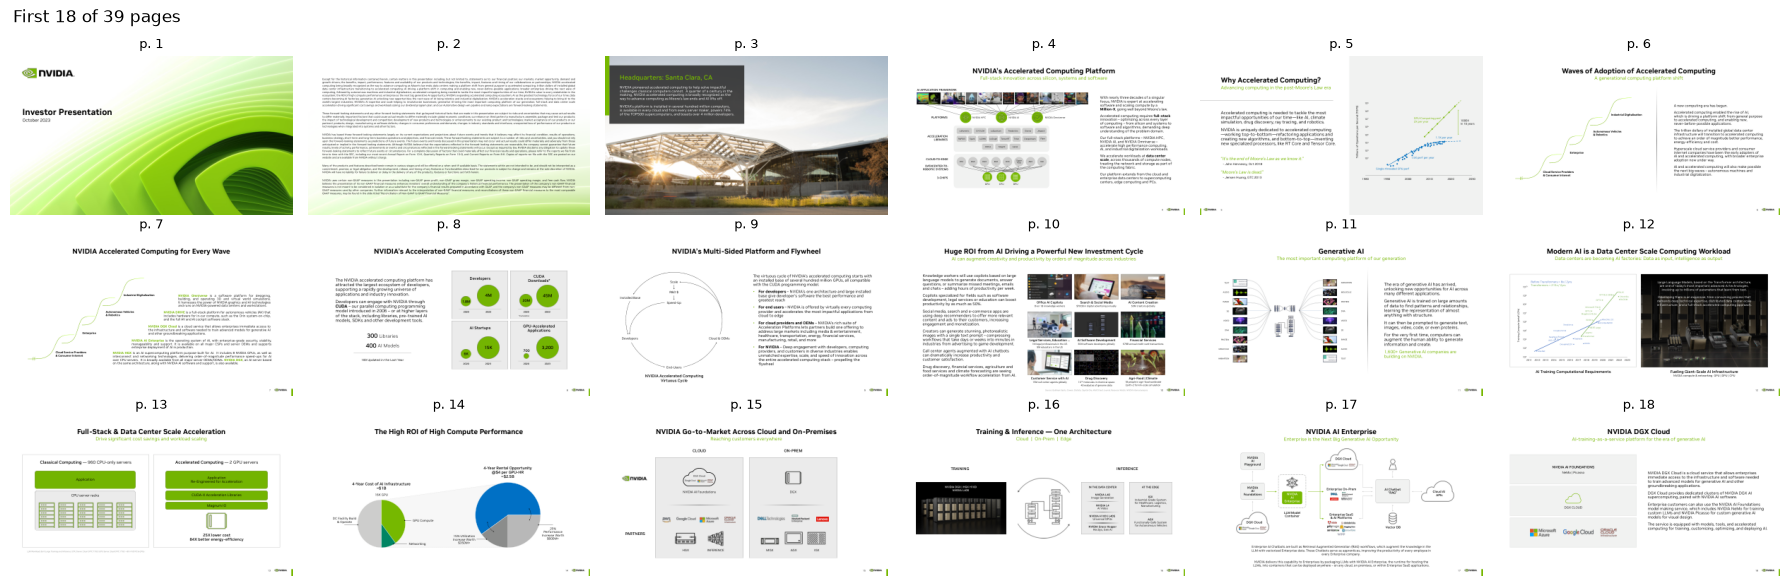

In [3]:
PDF_URL = "https://s201.q4cdn.com/141608511/files/doc_presentations/2023/Oct/01/ndr_presentation_oct_2023_final.pdf"
pdf_bytes = requests.get(PDF_URL, timeout=60).content
doc = pymupdf.open(stream=pdf_bytes, filetype="pdf")
NUM_PAGES = doc.page_count
PAGE_TEXT = {n: " ".join(doc[n - 1].get_text().split()) for n in range(1, NUM_PAGES + 1)}
print(f"{NUM_PAGES} pages")


def render_page(page: int, width: int = 1024, clip=None) -> Image.Image:
    """Render a 1-indexed page (or a clipped region of it) to a PIL image `width` pixels wide."""
    p = doc[page - 1]
    region = clip or p.rect
    zoom = width / region.width
    pix = p.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), clip=clip)
    return Image.frombytes("RGB", (pix.width, pix.height), pix.samples)


def to_data_url(image: Image.Image) -> str:
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=85)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()


fig, axes = plt.subplots(3, 6, figsize=(18, 6))
for ax, page in zip(axes.flat, range(1, 19)):
    ax.imshow(render_page(page, width=400))
    ax.set_title(f"p. {page}", fontsize=9)
    ax.axis("off")
plt.suptitle("First 18 of 39 pages", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Why text-only RAG struggles here

Here is page 21, one of the most information-dense slides in the deck:

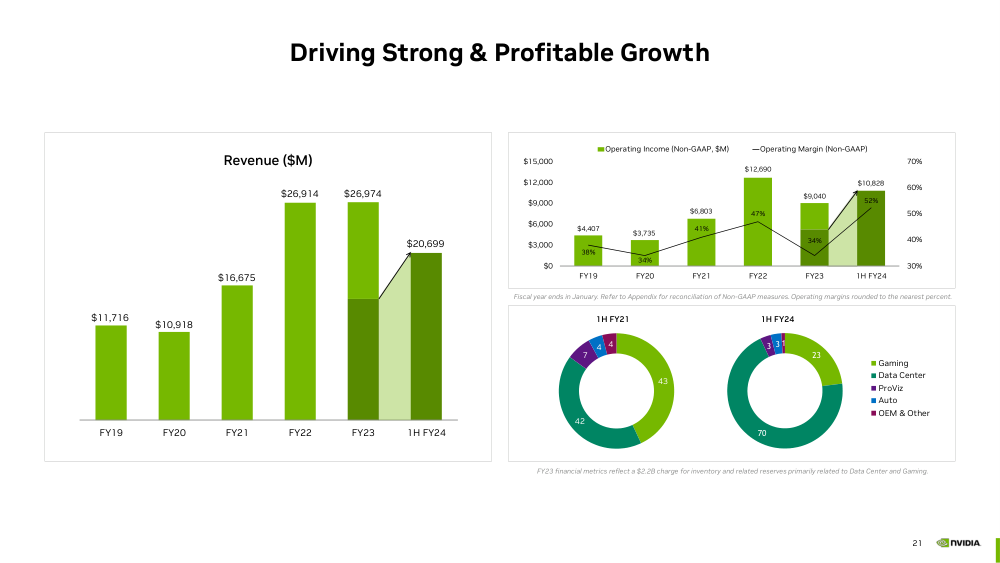

In [4]:
display(render_page(21, width=1000))

And here is what a text-based pipeline would embed for the same page. All the numbers are present, but nothing connects `70` to "Data Center" or `52%` to "1H FY24". A chunk-and-embed pipeline could retrieve this page, and the model would still have to guess which number belongs to which label.

In [5]:
print(PAGE_TEXT[21])

21 43 42 7 4 4 23 70 3 3 1 Gaming Data Center ProViz Auto OEM & Other Driving Strong & Profitable Growth $11,716 $10,918 $16,675 $26,914 $26,974 $20,699 FY19 FY20 FY21 FY22 FY23 1H FY24 Revenue ($M) Fiscal year ends in January. Refer to Appendix for reconciliation of Non-GAAP measures. Operating margins rounded to the nearest percent. FY23 financial metrics reflect a $2.2B charge for inventory and related reserves primarily related to Data Center and Gaming. $4,407 $3,735 $6,803 $12,690 $9,040 $10,828 38% 34% 41% 47% 34% 52% 30% 40% 50% 60% 70% $0 $3,000 $6,000 $9,000 $12,000 $15,000 FY19 FY20 FY21 FY22 FY23 1H FY24 Operating Income (Non-GAAP, $M) Operating Margin (Non-GAAP) 1H FY24 1H FY21


## Build the tools

The agent gets three tools:

| Tool | What it does | Why |
| :-- | :-- | :-- |
| `search_text(query)` | Keyword search over each page's text layer; returns page numbers and snippets | Cheap way to find candidate pages. No embeddings needed: titles and labels survive in the text layer even when chart values don't |
| `view_pages(pages)` | Returns up to 3 rendered pages as images | Lets the model actually read charts and diagrams |
| `zoom_page(page, region)` | Returns one region of a page at high resolution | Small legends and donut labels are hard to read at full-page resolution |

The model also sees a one-line outline of every page in its system prompt, so it can often jump straight to the right page.

In [6]:
ZOOM_REGIONS = {
    "top-left": (0, 0, 0.5, 0.5),
    "top-right": (0.5, 0, 1, 0.5),
    "bottom-left": (0, 0.5, 0.5, 1),
    "bottom-right": (0.5, 0.5, 1, 1),
    "top": (0, 0, 1, 0.5),
    "bottom": (0, 0.5, 1, 1),
    "left": (0, 0, 0.5, 1),
    "right": (0.5, 0, 1, 1),
}


def search_text(query: str, k: int = 5) -> str:
    terms = [t for t in re.findall(r"[a-z0-9]+", query.lower()) if len(t) > 2]
    scores = []
    for page, text in PAGE_TEXT.items():
        lowered = text.lower()
        score = sum(lowered.count(term) for term in terms)
        if score:
            scores.append((score, page))
    scores.sort(reverse=True)
    lines = [f"page {page} (score {score}): {PAGE_TEXT[page][:200]}" for score, page in scores[:k]]
    return "\n".join(lines) or "No matching pages."


def view_pages(pages: list[int]) -> list[dict]:
    content = []
    for page in pages:
        content.append({"type": "text", "text": f"[page {page}]"})
        content.append({"type": "image_url", "image_url": {"url": to_data_url(render_page(page))}})
    return content


def zoom_page(page: int, region: str) -> list[dict]:
    x0, y0, x1, y1 = ZOOM_REGIONS[region]
    r = doc[page - 1].rect
    clip = pymupdf.Rect(r.x0 + x0 * r.width, r.y0 + y0 * r.height, r.x0 + x1 * r.width, r.y0 + y1 * r.height)
    image = render_page(page, width=1280, clip=clip)
    return [{"type": "text", "text": f"[page {page}, {region}]"}, {"type": "image_url", "image_url": {"url": to_data_url(image)}}]


TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "search_text",
            "description": "Keyword search over the text layer of every page. Returns matching page numbers with a snippet. "
            "Numbers inside charts are often jumbled in the text layer, so view a page before quoting numbers from it.",
            "parameters": {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]},
        },
    },
    {
        "type": "function",
        "function": {
            "name": "view_pages",
            "description": "Look at up to 3 pages as images. Use this to read charts, tables, and diagrams.",
            "parameters": {
                "type": "object",
                "properties": {"pages": {"type": "array", "items": {"type": "integer"}}},
                "required": ["pages"],
            },
        },
    },
    {
        "type": "function",
        "function": {
            "name": "zoom_page",
            "description": "View one region of a page at high resolution. Use it to read small labels, legends, and donut or pie charts.",
            "parameters": {
                "type": "object",
                "properties": {"page": {"type": "integer"}, "region": {"type": "string", "enum": list(ZOOM_REGIONS)}},
                "required": ["page", "region"],
            },
        },
    },
]

print(search_text("data center revenue"))

page 24 (score 10): 24 Our Market Platforms at a Glance FY23 Revenue $15.0B 5-yr CAGR 51% FY23 Revenue $9.1B 5-yr CAGR 10% FY23 Revenue $1.5B 5-yr CAGR 11% FY23 Revenue $0.9B 5-yr CAGR 10% DGX/HGX/MGX/IGX systems GPU | C
page 28 (score 9): 28 Addressing the Entire Data Center FY20 FY21 FY22 FY23 Q2 FY24 Annualized Servers Network Infrastructure Other Data Center Infrastructure Server CPU NVIDIA Data Center Source: Mercury Research, Dell
page 2 (score 8): 2 Except for the historical information contained herein, certain matters in this presentation including, but not limited to, statements as to: our financial position; our markets, market opportunity,
page 12 (score 7): 12 Modern AI is a Data Center Scale Computing Workload Data centers are becoming AI factories: Data as input, intelligence as output AI Training Computational Requirements Fueling Giant-Scale AI Infra
page 4 (score 7): 4 NVIDIA’s Accelerated Computing Platform Full-stack innovation across silicon, systems and software c

## The agent loop

The loop is the standard function-calling pattern: call the model, run any tools it asks for, append the results, repeat until it answers in plain text.

Two details are specific to vision. First, images go inside tool results: a tool message's `content` can be a list of text and `image_url` parts, so `view_pages` hands the model the rendered pages directly. Second, Nemotron 3.5 Super VL accepts at most 32 images per request. Every page the agent looks at stays in the conversation, so we cap each call at 3 pages and check the running image count before each request.

In [7]:
OUTLINE = "\n".join(f"page {n}: {PAGE_TEXT[n][:90]}" for n in range(1, NUM_PAGES + 1))

SYSTEM_PROMPT = f"""You answer questions about a {NUM_PAGES}-page NVIDIA investor presentation from October 2023. You cannot see the document until you use tools.

How to work:
- Use the outline below or search_text to find candidate pages, then view_pages to read them. Numbers in charts must be read from the page images.
- For donut charts, pie charts, and small labels, use zoom_page and match each value to its legend color before answering.
- Answer only from pages you have viewed. Cite pages like [p. 21]. Keep the final answer to 2-4 sentences.

Outline (first words of each page):
{OUTLINE}"""

MAX_IMAGES = 32
MAX_PAGES_PER_VIEW = 3


def count_images(messages) -> int:
    return sum(
        1
        for m in messages
        if isinstance(m.get("content"), list)
        for part in m["content"]
        if part.get("type") == "image_url"
    )


def run_agent(question: str, max_steps: int = 10, verbose: bool = True) -> dict:
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    trace, usage = [], {"input_tokens": 0, "output_tokens": 0}
    start = time.time()
    for step in range(max_steps):
        response = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, max_tokens=8000)
        usage["input_tokens"] += response.usage.prompt_tokens
        usage["output_tokens"] += response.usage.completion_tokens
        message = response.choices[0].message
        if not message.tool_calls:
            return {"answer": message.content, "trace": trace, "steps": step + 1, "seconds": time.time() - start, **usage}
        messages.append(
            {"role": "assistant", "content": message.content or "", "tool_calls": [tc.model_dump() for tc in message.tool_calls]}
        )
        for call in message.tool_calls:
            name, args = call.function.name, json.loads(call.function.arguments or "{}")
            images_left = MAX_IMAGES - count_images(messages)
            if name == "search_text":
                result = search_text(args.get("query", ""))
            elif name == "view_pages":
                pages = [p for p in args.get("pages", []) if isinstance(p, int) and 1 <= p <= NUM_PAGES]
                pages = pages[: min(MAX_PAGES_PER_VIEW, images_left)]
                result = view_pages(pages) if pages else "No valid pages, or the image budget is used up. Answer from what you have."
            elif name == "zoom_page":
                page, region = args.get("page"), args.get("region")
                valid = isinstance(page, int) and 1 <= page <= NUM_PAGES and region in ZOOM_REGIONS and images_left > 0
                result = zoom_page(page, region) if valid else "Invalid page or region, or the image budget is used up."
            else:
                result = f"Unknown tool {name}"
            trace.append(f"{name}({', '.join(f'{k}={v!r}' for k, v in args.items())})")
            if verbose:
                print("  ->", trace[-1])
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    return {"answer": "(step limit reached)", "trace": trace, "steps": max_steps, "seconds": time.time() - start, **usage}

## Ask a question

Let's ask something whose answer is only in a chart:

In [8]:
result = run_agent("How much did NVIDIA's developer count grow between 2020 and 2023?")
display(Markdown(result["answer"]))
cost = (result["input_tokens"] * PRICE_IN + result["output_tokens"] * PRICE_OUT) / 1e6
print(f"\n{result['steps']} model calls, {result['input_tokens']:,} input tokens, {result['seconds']:.1f}s, ${cost:.4f}")

  -> view_pages(pages=[8])


NVIDIA's developer count grew from 1.8 million in 2020 to 4 million in 2023, an increase of 2.2 million developers (more than doubling). [p. 8]


2 model calls, 4,584 input tokens, 1.3s, $0.0008


Here's the page it read. The developer counts sit inside bubbles, and in the text layer they appear in the wrong order (`4M 1.8M`), so this question can't be answered reliably from the text alone:

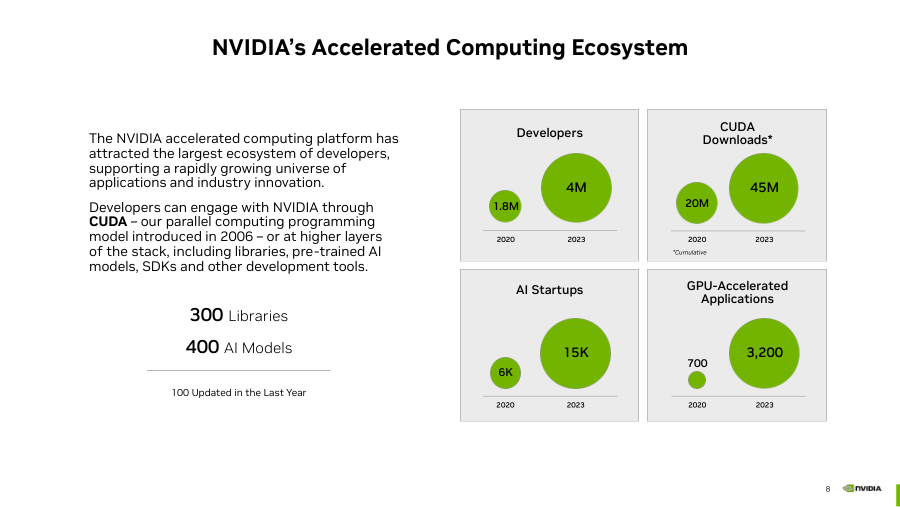

In [9]:
display(render_page(8, width=900))

## Evaluate on six questions

One correct answer doesn't tell us much, so we wrote six questions and checked their answers by hand against the slides. They cover chart reading, a donut chart with small labels, a roadmap diagram, a question that needs two pages, and an arithmetic step. Each question has a list of facts (as regular expressions) that a correct answer must contain.

In [10]:
EVAL = [
    {
        "question": "By what factor did NVIDIA's developer count grow from 2020 to 2023, and how many cumulative CUDA downloads were there by 2023?",
        "must_include": [r"2\.2", r"45\s?(M|million)"],
        "source": "p. 8: 1.8M -> 4M developers; 45M CUDA downloads",
    },
    {
        "question": "What was NVIDIA's non-GAAP operating margin in 1H FY24, and how many percentage points higher was that than in FY23?",
        "must_include": [r"52", r"\b1[89]"],
        "source": "p. 21 and p. 37: 52% (52.3%) vs 34% (33.5%)",
    },
    {
        "question": "What share of NVIDIA's revenue came from Data Center in 1H FY24, compared with 1H FY21?",
        "must_include": [r"70\s?(%|percent)", r"42\s?(%|percent)"],
        "source": "p. 21 donut charts: 70% vs 42%",
    },
    {
        "question": "On NVIDIA's roadmap slide, which product succeeds B100 for x86 training and inference, and in what year?",
        "must_include": [r"X100", r"2025"],
        "source": "p. 26: X100, 2025",
    },
    {
        "question": "In 1H FY24, roughly how many times larger was Data Center revenue than Gaming revenue?",
        "must_include": [r"\b3(\.\d)?\s?(x|×|times)|three times|\b3\.1\b"],
        "source": "p. 25 and p. 29: $14,607M / $4,726M = 3.1x",
    },
    {
        "question": "In the BERT-Large example, how many CPU-only servers are replaced by how many GPU servers, and what are the cost and energy-efficiency gains?",
        "must_include": [r"960", r"\b2\b", r"25\s?(x|×|times)", r"84\s?(x|×|times)"],
        "source": "p. 13: 960 CPU servers vs 2 GPU servers; 25X lower cost, 84X better energy efficiency",
    },
]


def is_correct(answer: str, must_include: list[str]) -> bool:
    return all(re.search(pattern, answer or "", re.IGNORECASE) for pattern in must_include)


agent_rows = []
for item in EVAL:
    print(f"\nQ: {item['question']}")
    r = run_agent(item["question"])
    print(f"A: {r['answer']}")
    agent_rows.append(
        {
            "question": item["question"][:60] + "...",
            "correct": is_correct(r["answer"], item["must_include"]),
            "model_calls": r["steps"],
            "input_tokens": r["input_tokens"],
            "output_tokens": r["output_tokens"],
            "seconds": round(r["seconds"], 1),
            "cost_usd": (r["input_tokens"] * PRICE_IN + r["output_tokens"] * PRICE_OUT) / 1e6,
        }
    )

agent_df = pd.DataFrame(agent_rows)
agent_df


Q: By what factor did NVIDIA's developer count grow from 2020 to 2023, and how many cumulative CUDA downloads were there by 2023?


  -> search_text(query='Developers CUDA downloads 2020 2023 million')
  -> zoom_page(page=8, region='top')


A: NVIDIA's developer count grew from 1.8 million in 2020 to 4 million in 2023, an increase of approximately 2.2x. Cumulative CUDA downloads reached 45 million by 2023, up from 20 million in 2020. [p. 8]

Q: What was NVIDIA's non-GAAP operating margin in 1H FY24, and how many percentage points higher was that than in FY23?


  -> search_text(query='non-GAAP operating margin 1H FY24 FY23 percentage')
  -> view_pages(pages=[21, 22, 37])


A: NVIDIA's non-GAAP operating margin in 1H FY24 was 52.3%, which was 18.8 percentage points higher than the 33.5% margin in FY23. [p. 37]

Q: What share of NVIDIA's revenue came from Data Center in 1H FY24, compared with 1H FY21?


...

  -> view_pages(pages=[29])


A: In 1H FY24, Data Center revenue was $14.607 billion, while Gaming revenue was $4.726 billion [p. 25][p. 29]. This means Data Center revenue was roughly 3.1 times larger than Gaming revenue.

Q: In the BERT-Large example, how many CPU-only servers are replaced by how many GPU servers, and what are the cost and energy-efficiency gains?


  -> search_text(query='BERT-Large CPU-only servers replaced GPU servers cost energy')
  -> view_pages(pages=[13, 14])


A: In the BERT-Large example, 960 CPU-only servers are replaced by just 2 GPU servers, delivering 25X lower cost and 84X better energy efficiency. [p. 13]


,question,correct,model_calls,input_tokens,output_tokens,seconds,cost_usd
0,By what factor did NVIDIA's developer count gr...,True,2,4932,808,1.8,0.001144
1,What was NVIDIA's non-GAAP operating margin in...,True,2,6293,665,1.7,0.001276
2,What share of NVIDIA's revenue came from Data ...,True,5,16562,2274,5.6,0.003621
3,"On NVIDIA's roadmap slide, which product succe...",True,2,4598,2538,5.0,0.001959
4,"In 1H FY24, roughly how many times larger was ...",True,3,7815,388,1.5,0.001366
5,"In the BERT-Large example, how many CPU-only s...",True,2,5637,365,1.2,0.001028


## Baseline: put the whole deck in context

With a 262K-token context window, why not skip the tools and send every page with every question? The first obstacle is the 32-image limit: the deck has 39 pages. We work around it by tiling four pages into each image (a 2x2 contact sheet with the page number stamped on each tile), which fits the whole deck into 10 images.

10 contact sheets of 1536x864 pixels


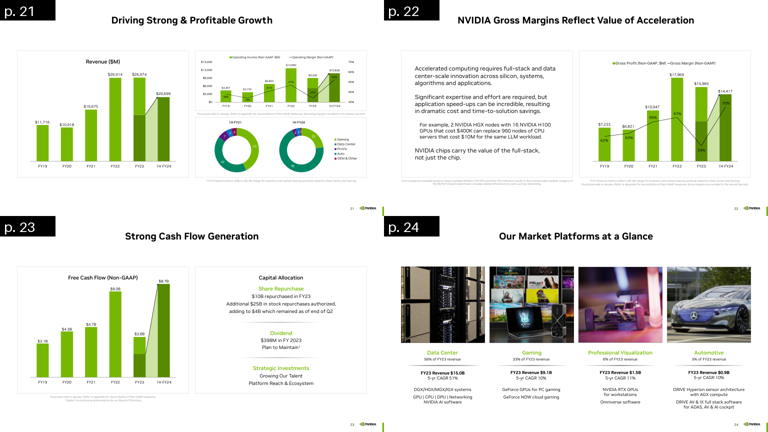

In [11]:
TILE_WIDTH = 768


def contact_sheet(pages: list[int]) -> Image.Image:
    tiles = [render_page(p, width=TILE_WIDTH) for p in pages]
    w, h = tiles[0].size
    sheet = Image.new("RGB", (2 * w, 2 * h), "white")
    draw = ImageDraw.Draw(sheet)
    font = ImageFont.load_default(size=28)
    for i, (page, tile) in enumerate(zip(pages, tiles)):
        x, y = (i % 2) * w, (i // 2) * h
        sheet.paste(tile, (x, y))
        draw.rectangle([x, y, x + 110, y + 40], fill="black")
        draw.text((x + 8, y + 4), f"p. {page}", fill="white", font=font)
    return sheet


sheets = [contact_sheet(list(range(start, min(start + 4, NUM_PAGES + 1)))) for start in range(1, NUM_PAGES + 1, 4)]
sheet_urls = [to_data_url(s) for s in sheets]
print(f"{len(sheets)} contact sheets of {sheets[0].size[0]}x{sheets[0].size[1]} pixels")
display(sheets[5].resize((sheets[5].width // 2, sheets[5].height // 2)))

In [12]:
STUFF_PROMPT = "These images contain every page of an NVIDIA investor presentation from October 2023, four pages per image, each labeled with its page number. Answer from the pages, cite pages like [p. 21], and keep the answer to 2-4 sentences."


def ask_whole_deck(question: str) -> dict:
    content = [{"type": "image_url", "image_url": {"url": url}} for url in sheet_urls]
    content.append({"type": "text", "text": question})
    start = time.time()
    response = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": STUFF_PROMPT}, {"role": "user", "content": content}],
        max_tokens=16000,
    )
    return {
        "answer": response.choices[0].message.content,
        "finish_reason": response.choices[0].finish_reason,
        "seconds": time.time() - start,
        "input_tokens": response.usage.prompt_tokens,
        "output_tokens": response.usage.completion_tokens,
    }


stuff_rows = []
for item in EVAL:
    r = ask_whole_deck(item["question"])
    print(f"\nQ: {item['question']}\nA: {r['answer']}  [finish_reason={r['finish_reason']}]")
    stuff_rows.append(
        {
            "question": item["question"][:60] + "...",
            "correct": is_correct(r["answer"], item["must_include"]),
            "input_tokens": r["input_tokens"],
            "output_tokens": r["output_tokens"],
            "seconds": round(r["seconds"], 1),
            "cost_usd": (r["input_tokens"] * PRICE_IN + r["output_tokens"] * PRICE_OUT) / 1e6,
        }
    )

stuff_df = pd.DataFrame(stuff_rows)
stuff_df


Q: By what factor did NVIDIA's developer count grow from 2020 to 2023, and how many cumulative CUDA downloads were there by 2023?
A: NVIDIA's developer count grew from 1.8 million in 2020 to 4 million in 2023, representing a growth factor of approximately 2.2x. By 2023, cumulative CUDA downloads reached 45 million [p. 8].  [finish_reason=stop]



Q: What was NVIDIA's non-GAAP operating margin in 1H FY24, and how many percentage points higher was that than in FY23?
A: None  [finish_reason=length]



Q: What share of NVIDIA's revenue came from Data Center in 1H FY24, compared with 1H FY21?
A: Based on the revenue mix charts on page 21, NVIDIA's Data Center segment accounted for **36%** of revenue in 1H FY21, compared to **76%** in 1H FY24. [p. 21]  [finish_reason=stop]



Q: On NVIDIA's roadmap slide, which product succeeds B100 for x86 training and inference, and in what year?
A: On page 26, the roadmap slide shows that the **X100** succeeds the B100 for **x86 Training & Inference** in **2025**.  [finish_reason=stop]



Q: In 1H FY24, roughly how many times larger was Data Center revenue than Gaming revenue?
A: Based on the charts on page 25 and page 29, Data Center revenue for 1H FY24 was $14,607 million, while Gaming revenue for the same period was $4,726 million. Dividing $14,607 million by $4,726 million results in approximately 3.1.

Roughly 3 times larger.  [finish_reason=stop]



Q: In the BERT-Large example, how many CPU-only servers are replaced by how many GPU servers, and what are the cost and energy-efficiency gains?
A: In the BERT-Large example detailed on page 13, 960 CPU-only servers are replaced by 2 GPU servers, achieving 25X lower cost and 84X better energy-efficiency.  [finish_reason=stop]


,question,correct,input_tokens,output_tokens,seconds,cost_usd
0,By what factor did NVIDIA's developer count gr...,True,13145,2033,5.2,0.002988
1,What was NVIDIA's non-GAAP operating margin in...,False,13139,16000,30.8,0.009971
2,What share of NVIDIA's revenue came from Data ...,False,13134,11819,22.9,0.007880
3,"On NVIDIA's roadmap slide, which product succe...",True,13134,2360,6.4,0.003150
4,"In 1H FY24, roughly how many times larger was ...",True,13126,1452,4.0,0.002695
5,"In the BERT-Large example, how many CPU-only s...",True,13137,1791,5.1,0.002866


## Compare

In [13]:
comparison = pd.DataFrame(
    [
        {
            "approach": name,
            "correct": f"{int(df.correct.sum())} / {len(df)}",
            "avg_input_tokens": int(df.input_tokens.mean()),
            "avg_seconds": round(df.seconds.mean(), 1),
            "avg_cost_usd": round(df.cost_usd.mean(), 5),
            "usd_per_1k_questions": round(df.cost_usd.mean() * 1000, 2),
        }
        for name, df in [("Agent (search + view + zoom)", agent_df), ("Whole deck in context (10 contact sheets)", stuff_df)]
    ]
)
comparison

,approach,correct,avg_input_tokens,avg_seconds,avg_cost_usd,usd_per_1k_questions
0,Agent (search + view + zoom),6 / 6,7639,2.8,0.00173,1.73
1,Whole deck in context (10 contact sheets),4 / 6,13135,12.4,0.00492,4.92


## What we found

In our run, the agent answered all six questions correctly for well under a cent each. Putting the whole deck in context got four right, cost almost three times as much per question, and took about four times as long. Model outputs vary between runs, so expect the occasional miss from either approach. The donut-chart question is the most fragile, which is why the agent has a zoom tool and a prompt rule about legend colors.

The agent does better because it sends one to three full-resolution pages per question instead of the whole document. The 262K context window holds the entire deck, but the 32-image cap forced four pages into each image, and at that resolution the model misread a donut chart. On another question it reasoned until it hit the output limit and never answered.

Keyword search over the text layer, plus a one-line outline of each page, was enough for the agent to find the right slide for every question. The page images then supplied the numbers that the text layer scrambles.

Whole-document context still has a place. For a question like "summarize every business segment," one pass over the contact sheets is simpler than an agent loop. For questions about specific numbers, the agent was cheaper, faster, and more accurate here.

### Next steps

- To use your own PDF, change `PDF_URL`. For scanned documents with no text layer, replace `search_text` with a short caption per page, generated once and cached.
- For a collection of documents, add a `list_documents` tool and a document id argument to each page tool. No vector index is needed for that either.
- Add a thumbnail mode to `view_pages` (several low-resolution pages in one image) so the agent can skim a section before zooming in.